# Module 11 · Gaussian processes, kernels, and prediction uncertainty
**Applied Stochastic Processes: Modeling, Simulation, and AI**

Practical question: **How do assumptions about covariance change a prediction and the uncertainty we report?**

Guided work: about 45–55 minutes. Investigations: about 25–35 minutes. This is **Concept Lab 6, Part A (week 11)**. Combine it with Module 12, Part B, in **one submission due in week 12**. The sustained course project continues; there is no additional project.

[Course home](../index.html) · [Interactive lesson](../modules/module11.html) · [Project guide](../project-guide.html)

We first condition a small synthetic Gaussian example. We then test two prespecified Gaussian proxies for **observed daily bike-rental counts**. The distinction between latent-process uncertainty and a future noisy observation matters in both examples.

## 1. A process described by finite Gaussian vectors
A Gaussian process (GP) $f\sim\operatorname{GP}(m,k)$ has a jointly Gaussian vector at **every finite set** of inputs:
$$\mathbf f=(f(x_1),\ldots,f(x_n))^T\sim N(\mathbf m,K),\quad m_i=m(x_i),\quad K_{ij}=k(x_i,x_j).$$
Normal marginal distributions alone are insufficient: joint Gaussian structure is required. A valid kernel is symmetric and positive semidefinite (PSD): $a^TKa\ge0$ for every real vector $a$ and every finite input set. This quantity is $\operatorname{Var}(a^T\mathbf f)$. Degenerate Gaussian vectors are allowed, so a covariance matrix need not be invertible.

Three examples are
$$k_{\rm RBF}(s,t)=a^2\exp[-(s-t)^2/(2\ell^2)],\quad
k_{\rm exp}(s,t)=a^2\exp[-|s-t|/\ell],\quad k_{\rm BM}(s,t)=\min(s,t),\ s,t\ge0.$$
Here $a$ is marginal standard deviation for the stationary kernels, and $\ell>0$ has input units. RBF and exponential kernels depend only on the lag and have constant marginal variance $a^2$; Brownian covariance is nonstationary with variance $t$. The helper also supports scaled Brownian covariance $a^2\min(s,t)$ with diffusion scale $a$; standard Brownian motion uses $a=1$. Brownian motion also requires its continuous version and $W_0=0$. RBF gives much smoother behavior than exponential at the same scale; a grid plot alone cannot prove path regularity.

Before running: at separation $\ell$, what fraction of variance remains as covariance under each stationary kernel? Can a symmetric matrix with positive entries still fail to be a covariance matrix?

In [1]:
%matplotlib inline
from pathlib import Path
import hashlib, json, platform
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy.linalg import cholesky, cho_solve, solve_triangular
from scipy.stats import norm
from IPython.display import display
SEED, JITTER = 6231, 1e-10
Z80 = norm.ppf(0.9)
plt.rcParams.update({"figure.figsize": (10, 3.8), "font.size": 11})

In [2]:
def kernel(x, z, ell=1., amplitude=1., kind="rbf"):
    x, z = np.asarray(x, float), np.asarray(z, float)
    if ell <= 0 or amplitude <= 0:
        raise ValueError("Use positive length scale and amplitude")
    distance = np.abs(x[:, None]-z[None, :])
    if kind == "rbf": return amplitude**2*np.exp(-0.5*(distance/ell)**2)
    if kind == "exponential": return amplitude**2*np.exp(-distance/ell)
    if kind == "brownian":
        if min(x.min(), z.min()) < 0: raise ValueError("Brownian times must be nonnegative")
        return amplitude**2*np.minimum(x[:, None], z[None, :])
    raise ValueError("Choose rbf, exponential, or brownian")

In [3]:
grid = np.linspace(0, 6, 61)
checks = []
for kind in ["rbf", "exponential", "brownian"]:
    matrix = kernel(grid, grid, kind=kind)
    assert np.allclose(matrix, matrix.T)
    smallest = np.linalg.eigvalsh(matrix).min()
    assert smallest > -1e-10
    checks.append(dict(kernel=kind, minimum_eigenvalue=smallest, variance_at_0=matrix[0, 0]))
bad = np.array([[1., 2.], [2., 1.]])
contrast = np.array([1., -1.])
assert contrast @ bad @ contrast == -2
print("Invalid covariance gives variance:", contrast @ bad @ contrast)
display(pd.DataFrame(checks))

Invalid covariance gives variance: -2.0


,kernel,minimum_eigenvalue,variance_at_0
0,rbf,-1.108503e-15,1.0
1,exponential,4.999138e-02,1.0
2,brownian,0.000000e+00,0.0


A finite eigenvalue check can expose an invalid proposed matrix, but passing one grid does not prove a kernel is valid for all inputs. The three displayed kernels are known valid examples. Tiny negative computed eigenvalues near machine precision may be roundoff.

For a PSD matrix $K=U\Lambda U^T$, draw $\mathbf f=\mathbf m+U\Lambda^{1/2}\mathbf z$ with independent standard normals. This works even when $K$ is singular. The function below rejects nonfinite or asymmetric covariance matrices and materially negative eigenvalues and removes only roundoff negatives. It does not repair arbitrary invalid kernels. Samples are finite-grid joint draws; joining them with lines does not simulate all intervening values.

In [4]:
def gaussian_draws(mean, covariance, replicas=4, seed=SEED):
    covariance = np.asarray(covariance, float)
    if covariance.shape != (len(mean), len(mean)) or not np.isfinite(covariance).all():
        raise ValueError("Finite square covariance matching the mean required")
    if not np.allclose(covariance, covariance.T, atol=1e-12, rtol=1e-10): raise ValueError("Covariance must be symmetric")
    symmetric = (covariance+covariance.T)/2
    eigenvalues, vectors = np.linalg.eigh(symmetric)
    tolerance = 1e-10*max(1., np.max(np.abs(eigenvalues)))
    if eigenvalues.min() < -tolerance:
        raise ValueError("Covariance has a materially negative eigenvalue")
    factor = vectors*np.sqrt(np.maximum(eigenvalues, 0))
    normals = np.random.default_rng(seed).normal(size=(len(mean), replicas))
    return np.asarray(mean)[:, None]+factor@normals
prior_rbf = gaussian_draws(np.zeros(len(grid)), kernel(grid, grid))
prior_exp = gaussian_draws(np.zeros(len(grid)), kernel(grid, grid, kind="exponential"))
assert np.all(kernel(grid, grid, kind="brownian")[0] == 0)

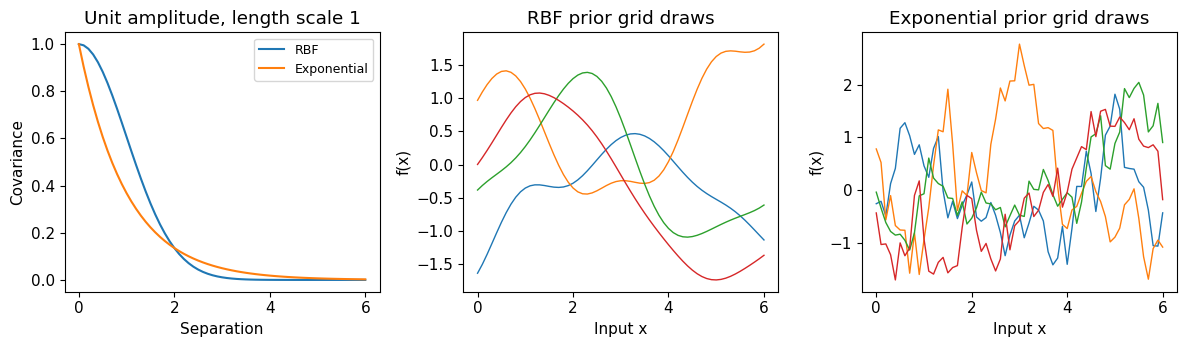

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for kind, label in [("rbf", "RBF"), ("exponential", "Exponential")]:
    axes[0].plot(grid, kernel([0], grid, kind=kind)[0], label=label)
axes[0].set(xlabel="Separation", ylabel="Covariance", title="Unit amplitude, length scale 1")
axes[0].legend(fontsize=9)
for ax, draws, title in zip(axes[1:], [prior_rbf, prior_exp], ["RBF prior grid draws", "Exponential prior grid draws"]):
    ax.plot(grid, draws, linewidth=1)
    ax.set(xlabel="Input x", ylabel="f(x)", title=title)
fig.tight_layout(); plt.show()

## 2. Conditioning: uncertainty about which quantity?
The **assigned synthetic observations** are $x=(0,0.8,1.8,3,4.2)$ and $y=(0.2,1,-0.4,0.6,-0.2)$. They are an illustrative dataset, not an estimated bike mechanism. Assume
$$y_i=f(x_i)+\epsilon_i,\quad \epsilon_i\overset{\rm iid}{\sim}N(0,\sigma_n^2),\quad \epsilon\perp f.$$
With zero prior mean, let $A=K_{XX}+\sigma_n^2I$. Gaussian conditioning gives
$$\mu_*=K_{*X}A^{-1}\mathbf y,\qquad
\Sigma_f=K_{**}-K_{*X}A^{-1}K_{X*}.$$
For a **new noisy observation** with independent noise, $\Sigma_y=\Sigma_f+\sigma_n^2I$. A pointwise central 80% interval is $\mu_j\pm z_{0.9}\sqrt{\Sigma_{jj}}$. It is not an 80% simultaneous band for an entire path.

We compute solves, not an explicit inverse: factor $A+\delta I=LL^T$, solve for $\alpha=(A+\delta I)^{-1}y$, then $V=L^{-1}K_{X*}$ and $\Sigma_f=K_{**}-V^TV$. The small **jitter** $\delta=10^{-10}$ stabilizes computation; it is not a scientifically estimated noise variance and is not added to future observation uncertainty. It slightly perturbs the training solve, so noise-free interpolation below is approximate to numerical tolerance.

In [6]:
def posterior(x, y, target, ell=1., noise=0.2, kind="rbf", jitter=JITTER):
    if noise < 0 or jitter < 0:
        raise ValueError("Noise SD and jitter must be nonnegative")
    covariance = kernel(x, x, ell=ell, kind=kind)
    cross = kernel(x, target, ell=ell, kind=kind)
    lower = cholesky(covariance+(noise**2+jitter)*np.eye(len(x)), lower=True)
    alpha = cho_solve((lower, True), np.asarray(y, float))
    projected = solve_triangular(lower, cross, lower=True)
    latent = kernel(target, target, ell=ell, kind=kind)-projected.T@projected
    latent = (latent+latent.T)/2
    if np.diag(latent).min() < -1e-8:
        raise ValueError("Materially negative posterior variance")
    latent_variance = np.maximum(np.diag(latent), 0)
    return cross.T@alpha, latent, latent_variance+noise**2

In [7]:
x = np.array([0., 0.8, 1.8, 3., 4.2])
y = np.array([0.2, 1., -0.4, 0.6, -0.2])
mu, latent_cov, observed_variance = posterior(x, y, grid)
latent_sd, observed_sd = np.sqrt(np.maximum(np.diag(latent_cov), 0)), np.sqrt(observed_variance)
conditional_draws = gaussian_draws(mu, latent_cov, seed=SEED+1)
assert np.allclose(observed_variance-np.diag(latent_cov), 0.2**2)
assert np.all(np.diag(latent_cov) <= 1+1e-10)
locations = [0, 10, 30, 42, 60]
display(pd.DataFrame(dict(x=grid[locations], conditional_mean=mu[locations],
    latent_variance=np.diag(latent_cov)[locations], observation_variance=observed_variance[locations])))

,x,conditional_mean,latent_variance,observation_variance
0,0.0,0.289824,0.036410,0.076410
1,1.0,0.677992,0.037151,0.077151
2,3.0,0.501110,0.037057,0.077057
3,4.2,-0.153379,0.037901,0.077901
4,6.0,-0.203725,0.951879,0.991879


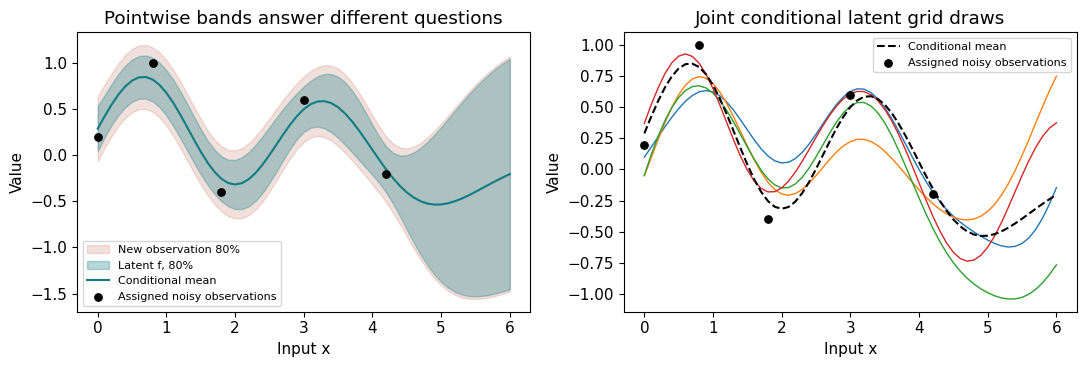

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].fill_between(grid, mu-Z80*observed_sd, mu+Z80*observed_sd, color="#bb573d", alpha=0.18, label="New observation 80%")
axes[0].fill_between(grid, mu-Z80*latent_sd, mu+Z80*latent_sd, color="#117c83", alpha=0.3, label="Latent f, 80%")
axes[0].plot(grid, mu, color="#117c83", label="Conditional mean")
axes[1].plot(grid, conditional_draws, linewidth=1)
axes[1].plot(grid, mu, "k--", label="Conditional mean")
for ax in axes:
    ax.scatter(x, y, c="black", s=28, zorder=4, label="Assigned noisy observations")
    ax.set(xlabel="Input x", ylabel="Value")
    ax.legend(fontsize=8)
axes[0].set_title("Pointwise bands answer different questions")
axes[1].set_title("Joint conditional latent grid draws")
fig.tight_layout(); plt.show()

The covariance describes dependence across predictions; independently drawing each grid coordinate from its marginal would lose that dependence. Under fixed kernel/noise parameters, the posterior covariance depends on input locations, not the observed $y$ values. A changed mean with unchanged variance after changing $y$ is therefore expected in this Gaussian model.

Before changing controls in the HTML: predict how a longer length scale, a rougher kernel, or larger assumed observation noise will affect interpolation. Noise is a standard deviation: square it before adding it to a covariance diagonal.

In [9]:
sensitivity_rows = []
for kind in ["rbf", "exponential"]:
    for ell in [0.3, 1., 2.]:
        for noise in [0., 0.2, 0.6]:
            mean_s, cov_s, var_s = posterior(x, y, grid, ell=ell, noise=noise, kind=kind)
            sensitivity_rows.append(dict(kernel=kind, ell=ell, noise_SD=noise,
                mean_at_6=mean_s[-1], latent_SD_at_6=np.sqrt(cov_s[-1, -1]),
                observation_SD_at_6=np.sqrt(var_s[-1])))
sensitivity = pd.DataFrame(sensitivity_rows)
display(sensitivity[(sensitivity.noise_SD == 0.2) | ((sensitivity.ell == 1) & (sensitivity.kernel == "rbf"))])

,kernel,ell,noise_SD,mean_at_6,latent_SD_at_6,observation_SD_at_6
1,rbf,0.3,0.2,-2.931677e-09,1.000000,1.019804
3,rbf,1.0,0.0,-2.648910e-01,0.973523,0.973523
4,rbf,1.0,0.2,-2.037247e-01,0.975643,0.995931
5,rbf,1.0,0.6,-7.582680e-02,0.983859,1.152380
7,rbf,2.0,0.2,-5.273462e-01,0.662157,0.691702
10,exponential,0.3,0.2,-4.756700e-04,0.999997,1.019801
13,exponential,1.0,0.2,-3.048003e-02,0.986774,1.006838
16,exponential,2.0,0.2,-7.034041e-02,0.917039,0.938595


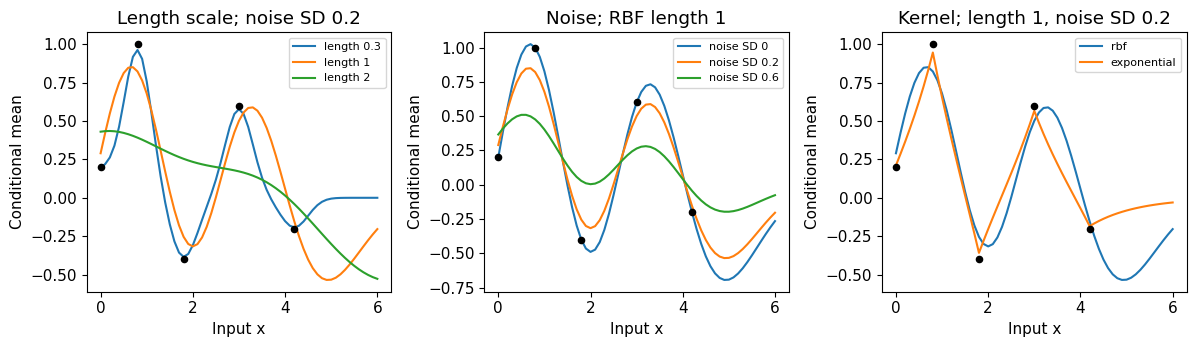

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ell in [0.3, 1., 2.]:
    mean_s, _, _ = posterior(x, y, grid, ell=ell)
    axes[0].plot(grid, mean_s, label=f"length {ell:g}")
for noise in [0., 0.2, 0.6]:
    mean_s, _, _ = posterior(x, y, grid, noise=noise)
    axes[1].plot(grid, mean_s, label=f"noise SD {noise:g}")
for kind in ["rbf", "exponential"]:
    mean_s, _, _ = posterior(x, y, grid, kind=kind)
    axes[2].plot(grid, mean_s, label=kind)
for ax, title in zip(axes, ["Length scale; noise SD 0.2", "Noise; RBF length 1", "Kernel; length 1, noise SD 0.2"]):
    ax.scatter(x, y, c="black", s=20, zorder=4)
    ax.set(xlabel="Input x", ylabel="Conditional mean", title=title)
    ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

## 3. Independent checks and limiting cases
With RBF length scale 2 and zero observation noise, the assigned points nearly interpolate, but the conditional mean at x=6 is about −9.004. This finite-distance extrapolation can overshoot strongly under an inflexible smooth, noiseless assumption. It is not a guarantee that the data or the solver are wrong. The mean returns to its zero prior value only sufficiently far from every observed input; x=6 is not yet that limit for this scenario.

For one datum at $x=0$ with $y=1$, unit prior variance, and kernel covariance $r=k(0,t)$, direct bivariate conditioning gives
$$E[f(t)\mid y]=\frac{r}{1+\sigma_n^2+\delta},\quad
\operatorname{Var}(f(t)\mid y)=1-\frac{r^2}{1+\sigma_n^2+\delta}.$$
This small independent calculation checks the multivariate solver. At distinct training inputs with $\sigma_n=0$, the posterior nearly interpolates; with large observation noise it approaches its prior. Noise-free duplicate observations can produce a singular training covariance; jitter is a numerical perturbation, not permission to fit contradictory duplicates as exact observations.

A link to Module 10 provides another benchmark: for Brownian covariance and $0<s<t$, $W_s\mid W_t=b\sim N(sb/t,s-s^2/t)$.

In [11]:
one_mean, one_cov, one_obs = posterior([0.], [1.], [1.], noise=0.2)
r = np.exp(-0.5)
assert np.allclose(one_mean, r/(1+0.2**2+JITTER))
assert np.allclose(one_cov[0, 0], 1-r*r/(1+0.2**2+JITTER))
interpolated, zero_cov, _ = posterior(x, y, x, noise=0.)
assert np.max(np.abs(interpolated-y)) < 1e-8 and np.max(np.diag(zero_cov)) < 1e-8
changed_mean, changed_cov, _ = posterior(x, y+1, grid)
assert np.allclose(changed_cov, latent_cov) and not np.allclose(changed_mean, mu)
bridge_mean, bridge_cov, _ = posterior([2.], [1.5], [0.5], noise=0., kind="brownian")
assert np.allclose([bridge_mean[0], bridge_cov[0, 0]], [0.375, 0.375])
print("PASS: scalar conditional formula, interpolation, y-invariant covariance, Brownian bridge")

PASS: scalar conditional formula, interpolation, y-invariant covariance, Brownian bridge


## 4. Bike-sharing data: a fixed-origin prediction experiment
The unchanged [UCI Bike Sharing sample](https://doi.org/10.24432/C5W894), Fanaee-T (2013), CC BY 4.0, has **365 observed system-wide daily completed-rental totals for 2011**. It does not measure a latent smooth demand curve, unmet demand, station inventory, or independent measurement errors. The decomposition $y=f+\epsilon$ is an assumed Gaussian count proxy; the residual term includes variation left unexplained by this model and should not be presented as known sensor error.

Fit only the **243 January–August observations**. Issue every **122 September–December prediction once at the August 31 origin**, with no updating or refitting using later outcomes. This differs from Module 10's rolling one-day protocol, which used each observed preceding day. Their scores answer different forecasting questions and must not be compared as the same task.

Use inputs $x=$ days since January 1. Estimate only training mean $\bar c$ and standard deviation $s_c$ (ddof=0), then standardize $z_i=(c_i-\bar c)/s_c$. Prespecify two RBF scenarios, **length scales 14 and 45 days**, unit standardized amplitude and **noise SD 0.5**. These are sensitivity assumptions, not hyperparameters optimized on September–December. Training standardization is also a plug-in estimate; its uncertainty is omitted.

In [12]:
candidates = [Path.cwd(), Path.cwd().parent]
ROOT = next(p for p in candidates if (p/"data/bike_daily_2011.csv").is_file())
data_path = ROOT/"data/bike_daily_2011.csv"
source = json.loads((ROOT/"data/source_metadata.json").read_text())
assert hashlib.sha256(data_path.read_bytes()).hexdigest() == source["sample_sha256"]
bike = pd.read_csv(data_path, parse_dates=["dteday"])
assert bike.dteday.tolist() == list(pd.date_range("2011-01-01", "2011-12-31"))
assert len(bike) == 365 and bike.dteday.is_unique and bike.cnt.ge(0).all()
assert np.all(bike.cnt == np.floor(bike.cnt))
training, later = bike.iloc[:243].copy(), bike.iloc[243:].copy()
assert training.dteday.max() == pd.Timestamp("2011-08-31")
assert len(later) == 122 and later.dteday.min() == pd.Timestamp("2011-09-01")
assert training.cnt.sum() == 802684 and later.cnt.sum() == 440419
print("Verified 365 daily observed counts: 243 training days, 122 reused development targets.")

Verified 365 daily observed counts: 243 training days, 122 reused development targets.


In [13]:
training_mean = training.cnt.mean()
training_sd = training.cnt.std(ddof=0)
train_x = (training.dteday-bike.dteday.iloc[0]).dt.days.to_numpy(float)
target_x = (later.dteday-bike.dteday.iloc[0]).dt.days.to_numpy(float)
train_z = (training.cnt.to_numpy(float)-training_mean)/training_sd
assert np.isclose(train_z.mean(), 0) and np.isclose(train_z.std(ddof=0), 1)
assert np.array_equal(train_x, np.arange(243)) and np.array_equal(target_x, np.arange(243, 365))
print("Estimated training mean and SD:", training_mean, training_sd)
print("Assumed scales: 14 or 45 days; amplitude 1; noise SD 0.5 standardized units.")
print("Implied noise SD in count units:", 0.5*training_sd)

Estimated training mean and SD: 3303.2263374485597 1487.7761991409216
Assumed scales: 14 or 45 days; amplitude 1; noise SD 0.5 standardized units.
Implied noise SD in count units: 743.8880995704608


Transform conditional means back as $\bar c+s_c\mu_*$ and variances as $s_c^2\Sigma$. Pointwise latent intervals describe the unobserved proxy $f$; evaluate **observed-count coverage using the wider new-observation intervals**. Both are conditional on the assumed kernel/noise and estimated standardization. They omit hyperparameter uncertainty and have no empirical coverage guarantee under misspecification.

As the RBF cross-covariance with training data tends to zero, the mean returns to $\bar c$, latent SD to $s_c$, and observation SD to $s_c\sqrt{1+0.5^2}$. Uncertainty approaches a finite prior level; it does not grow forever. The Gaussian model permits negative values and interval limits for count data. Keep these visible rather than silently clipping; clipping changes the predictive distribution and coverage interpretation.

In [14]:
forecasts, bike_latent_cov = {}, {}
for ell in [14., 45.]:
    mean_b, covariance_b, obs_variance_b = posterior(train_x, train_z, target_x, ell=ell, noise=0.5)
    prediction = later[["dteday", "cnt"]].copy()
    prediction["mean"] = training_mean+training_sd*mean_b
    prediction["latent_SD"] = training_sd*np.sqrt(np.maximum(np.diag(covariance_b), 0))
    prediction["observation_SD"] = training_sd*np.sqrt(obs_variance_b)
    prediction["lower"] = prediction["mean"]-Z80*prediction.observation_SD
    prediction["upper"] = prediction["mean"]+Z80*prediction.observation_SD
    prediction["covered"] = prediction.cnt.between(prediction.lower, prediction.upper)
    forecasts[ell], bike_latent_cov[ell] = prediction, covariance_b
assert np.allclose(forecasts[14.].observation_SD**2-forecasts[14.].latent_SD**2, (0.5*training_sd)**2)
print("Forecasts use only training inputs/outcomes; later outcomes enter scoring after prediction.")

Forecasts use only training inputs/outcomes; later outcomes enter scoring after prediction.


In [15]:
score_rows = []
for label, estimate in [("GP ell=14", forecasts[14.]["mean"]), ("GP ell=45", forecasts[45.]["mean"]),
                        ("Training mean", np.full(122, training_mean)),
                        ("Last training count", np.full(122, training.cnt.iloc[-1]))]:
    error = np.asarray(estimate)-later.cnt.to_numpy(float)
    score_rows.append(dict(model=label, targets=len(error), RMSE=np.sqrt(np.mean(error**2)), MAE=np.mean(np.abs(error))))
scores = pd.DataFrame(score_rows)
coverage = pd.DataFrame([dict(ell_days=ell, covered=int(f.covered.sum()), targets=len(f),
    observation_coverage=f.covered.mean(), mean_interval_width=np.mean(f.upper-f.lower)) for ell, f in forecasts.items()])
display(scores); display(coverage)
print("Far-horizon limits: mean", training_mean, "latent SD", training_sd,
      "observation SD", training_sd*np.sqrt(1.25))

,model,targets,RMSE,MAE
0,GP ell=14,122,1062.353022,861.229744
1,GP ell=45,122,985.247897,718.282887
2,Training mean,122,1137.700850,939.942960
3,Last training count,122,1815.760422,1478.745902


,ell_days,covered,targets,observation_coverage,mean_interval_width
0,14.0,113,122,0.926230,4062.936115
1,45.0,110,122,0.901639,3500.751094


Far-horizon limits: mean 3303.2263374485597 latent SD 1487.7761991409216 observation SD 1663.3843582926825


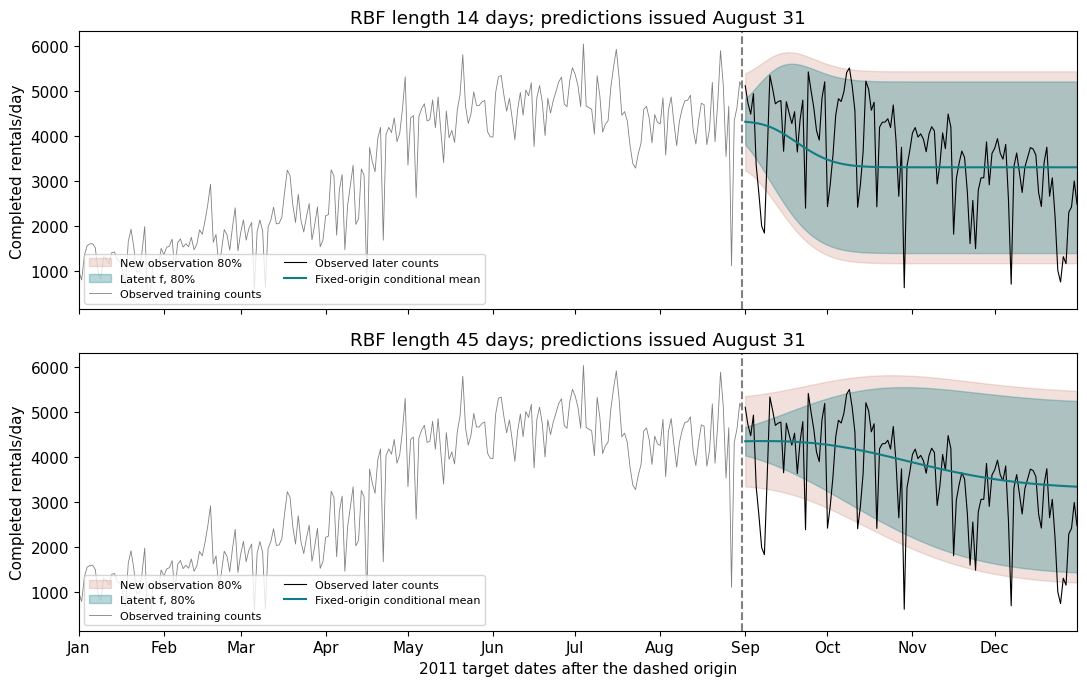

In [16]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
for ax, (ell, f) in zip(axes, forecasts.items()):
    ax.fill_between(f.dteday, f.lower.to_numpy(), f.upper.to_numpy(), color="#bb573d", alpha=0.18, label="New observation 80%")
    ax.fill_between(f.dteday, f["mean"]-Z80*f.latent_SD, f["mean"]+Z80*f.latent_SD, color="#117c83", alpha=0.3, label="Latent f, 80%")
    ax.plot(training.dteday, training.cnt, color="gray", linewidth=0.6, label="Observed training counts")
    ax.plot(f.dteday, f.cnt, color="black", linewidth=0.8, label="Observed later counts")
    ax.plot(f.dteday, f["mean"], color="#117c83", label="Fixed-origin conditional mean")
    ax.axvline(pd.Timestamp("2011-08-31"), color="gray", linestyle="--")
    ax.set(ylabel="Completed rentals/day", title=f"RBF length {ell:g} days; predictions issued August 31")
    ax.legend(fontsize=8, ncol=2, loc="lower left")
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b"))
axes[-1].set(xlabel="2011 target dates after the dashed origin", xlim=(bike.dteday.min(), bike.dteday.max()))
fig.tight_layout(); plt.show()

At the stated values, length 14 has RMSE **1062.35**, MAE **861.23**, and observation coverage **113/122 (92.6%)**, with mean interval width **4062.94 rentals/day**. Length 45 has RMSE **985.25**, MAE **718.28**, coverage **110/122 (90.2%)**, and width **3500.75**. The training-mean baseline has RMSE/MAE **1137.70/939.94**; the last-training-value baseline has **1815.76/1478.75**. Both prespecified GP scenarios beat these two point baselines on this comparison, while wide intervals overcover relative to nominal 80%.

Compare each forecast with both fixed-origin baselines on the same dates. The last-observed baseline is the August 31 count held constant; it is **not** rolling persistence. A good-looking smooth curve or wide interval is not enough: inspect prediction errors, width, and coverage together.

September–December has been reused in earlier modules. It is a **development comparison**, not a newly untouched final test set. Do not select a scenario using these scores and then call its same-period score an unbiased final evaluation.

In [17]:
horizon_rows = []
for ell, f in forecasts.items():
    for start, stop in [(1, 30), (31, 60), (61, 90), (91, 122)]:
        block = f.iloc[start-1:stop]
        horizon_rows.append(dict(ell_days=ell, horizon=f"{start}–{stop}", days=len(block),
            observation_coverage=block.covered.mean(), RMSE=np.sqrt(np.mean((block["mean"]-block.cnt)**2))))
horizon_scores = pd.DataFrame(horizon_rows)
display(horizon_scores)

,ell_days,horizon,days,observation_coverage,RMSE
0,14.0,1–30,30,0.900000,1078.261076
1,14.0,31–60,30,0.933333,1283.663590
2,14.0,61–90,30,1.000000,782.511624
3,14.0,91–122,32,0.875000,1045.907995
4,45.0,1–30,30,0.866667,959.387829
5,45.0,31–60,30,0.900000,1083.883050
6,45.0,61–90,30,0.966667,777.352924
7,45.0,91–122,32,0.875000,1081.692626


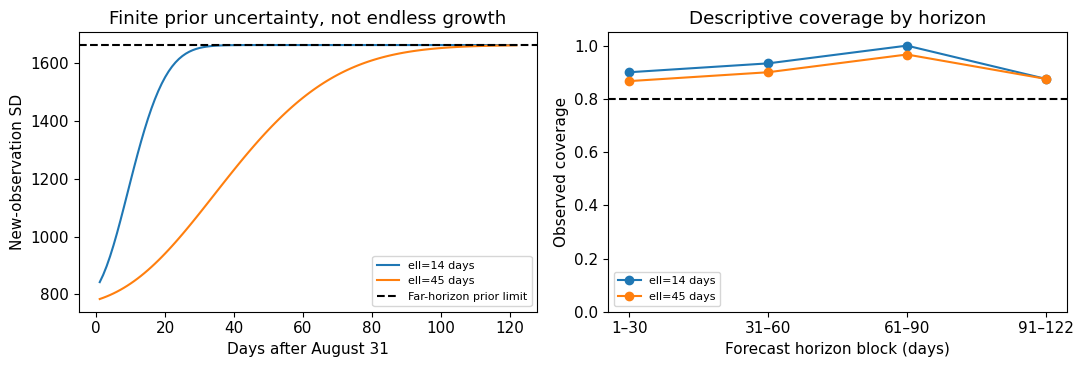

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ell, f in forecasts.items():
    axes[0].plot(np.arange(1, 123), f.observation_SD, label=f"ell={ell:g} days")
    block = horizon_scores[horizon_scores.ell_days == ell]
    axes[1].plot(block.horizon, block.observation_coverage, "o-", label=f"ell={ell:g} days")
axes[0].axhline(training_sd*np.sqrt(1.25), color="black", linestyle="--", label="Far-horizon prior limit")
axes[0].set(xlabel="Days after August 31", ylabel="New-observation SD", title="Finite prior uncertainty, not endless growth")
axes[1].axhline(0.8, color="black", linestyle="--"); axes[1].set(xlabel="Forecast horizon block (days)", ylabel="Observed coverage", ylim=(0, 1.05), title="Descriptive coverage by horizon")
for ax in axes: ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

## 5. What can residual diagnostics reveal?
For an in-training diagnostic, subtract the fitted latent conditional mean from each training observation. Plot standardized residuals $(z_i-\widehat f_i)/\sigma_n$ and their sample lag correlations. These residuals have been influenced by fitting to the same data, so they are **not independent predictive errors**, and their histogram or correlation is not a calibrated formal test. Visible dependence or unusual residual scale can still motivate model criticism.

Daily counts can depend on weather, weekday, season, and disruptions. The simple time-only Gaussian proxy assumes constant residual variance and independent observation noise, and it treats counts as real values. A smooth latent curve is not an observed demand mechanism or a causal effect. Finite prior uncertainty far from data is conditional on these assumptions, not a guarantee of reliable long-range prediction.

Training standardized residual RMS and lag-1 correlation: 0.7532109532448812 0.07401838092262555


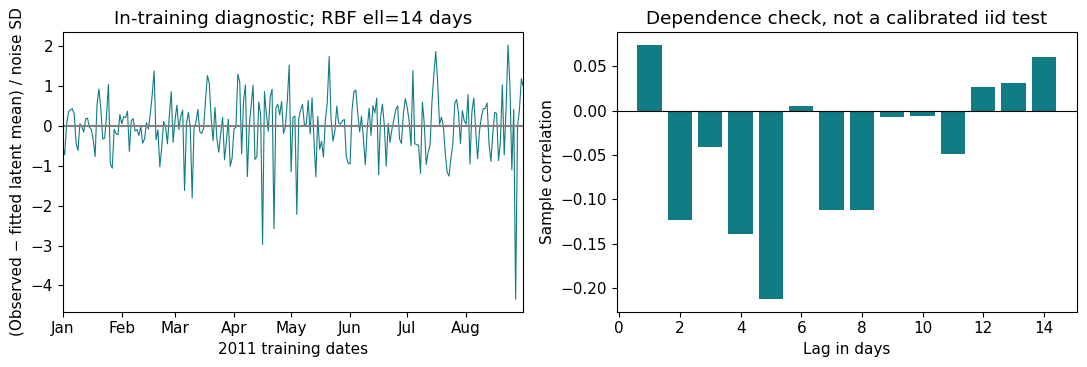

In [19]:
fit_z, _, _ = posterior(train_x, train_z, train_x, ell=14., noise=0.5)
standard_residual = (train_z-fit_z)/0.5
lags = np.arange(1, 15)
residual_acf = np.array([np.corrcoef(standard_residual[:-lag], standard_residual[lag:])[0, 1] for lag in lags])
print("Training standardized residual RMS and lag-1 correlation:", np.sqrt(np.mean(standard_residual**2)), residual_acf[0])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(training.dteday, standard_residual, color="#117c83", linewidth=0.8)
axes[0].axhline(0, color="gray"); axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%b"))
axes[0].set(xlabel="2011 training dates", ylabel="(Observed − fitted latent mean) / noise SD", title="In-training diagnostic; RBF ell=14 days", xlim=(training.dteday.min(), training.dteday.max()))
axes[1].bar(lags, residual_acf, color="#117c83")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set(xlabel="Lag in days", ylabel="Sample correlation", title="Dependence check, not a calibrated iid test")
fig.tight_layout(); plt.show()

## 6. Verify claims, including optional AI suggestions
An optional AI assistant proposes the following flawed lines. The activity works without an AI account or a paid API.
```python
scale = all_counts.std()
A = K + noise_sd * np.eye(n)
latent_cov = Kss - Ksx @ np.linalg.inv(A) @ Ksx.T
observation_band = mean + z * np.sqrt(np.diag(latent_cov))
# Advertised as simultaneous 80%; evaluated after tuning on September–December.
```
Check the squared units of noise, the complete conditioning covariance and stable solve, the predicted quantity, and the time split. Repair these using **two independent forms of evidence**, such as a scalar conditional-Gaussian calculation plus a numerical limiting case, or a date audit plus reconstruction from training-only statistics. Merely asking an AI to agree is not an independent check. Disclose consequential prompts and retained corrections if AI is used.

In [20]:
assert np.allclose(kernel([0, 1], [0, 1]), [[1, np.exp(-0.5)], [np.exp(-0.5), 1]])
assert np.allclose(kernel([0, 1], [0, 1], kind="exponential"), [[1, np.exp(-1)], [np.exp(-1), 1]])
assert np.allclose(training_mean, 3303.22633744856)
assert len(train_z) == 243 and all(len(f) == 122 for f in forecasts.values())
assert training.cnt.iloc[-1] == 5058
far_mean, far_cov, far_obs = posterior(train_x, train_z, [10000.], ell=45., noise=0.5)
assert np.allclose([far_mean[0], far_cov[0, 0], far_obs[0]], [0, 1, 1.25])
assert all(np.all(f.observation_SD >= f.latent_SD) for f in forecasts.values())
print("PASS: PSD examples, Gaussian conditioning, uncertainty decomposition, chronology, and far-input limit")
print("Runtime:", platform.python_version(), {p: metadata.version(p) for p in ["numpy", "pandas", "scipy", "matplotlib"]})

PASS: PSD examples, Gaussian conditioning, uncertainty decomposition, chronology, and far-input limit


Runtime: 3.10.9 {'numpy': '1.24.2', 'pandas': '2.0.0', 'scipy': '1.10.1', 'matplotlib': '3.7.1'}


## 7. Four investigations · your work
Keep the following cells unanswered in the distributed notebook. Submit the four concise investigations with Module 12 as **one Concept Lab 6 submission due in week 12**. The worked examples are templates for calculations and interpretation.

### E1 — Build and check a kernel
On x=[0,0.8,1.8,3,4.2], compare RBF and exponential covariance matrices with amplitude 1 and length scale 1. Check symmetry, diagonal variances, and eigenvalues; simulate 4000 independent Gaussian vectors and compare empirical covariance with the kernel. Explain why nonnegative matrix entries alone do not establish a valid covariance.

In [21]:
# YOUR WORK — E1
# Add your calculation and a short interpretation here.

### E2 — Separate two uncertainties
Use the five synthetic observations and RBF length scales 0.3, 1, and 2 with noise SD 0.2. Compare posterior means and central 80% latent and new-observation intervals. Repeat at noise SD 0 and 0.6; explain interpolation, far-field behavior, and why pointwise intervals are not a simultaneous path band.

In [22]:
# YOUR WORK — E2
# Add your calculation and a short interpretation here.

### E3 — Verify conditioning
For one observation y(0)=1, prior mean 0, amplitude 1, RBF length scale 1, and noise SD 0.5, compute the posterior mean and latent variance at x=1 by hand and by code. Check that adding noise changes new-observation variance by 0.25. Change y(0) to -1 while keeping inputs and parameters fixed; state which posterior quantities change. Distinguish jitter from noise and test a duplicate-input case.

In [23]:
# YOUR WORK — E3
# Add your calculation and a short interpretation here.

### E4 — Audit fixed-origin bike predictions
Fit centering and scaling using January–August only. Compare the two stated RBF scenarios with training-mean and last-training-value baselines on all 122 September–December targets, using a single August 31 origin. Report RMSE, MAE, new-observation 80% coverage, and interval width. Explain why later observations must not update this forecast, why scores are not directly comparable to Module 10’s rolling one-day protocol, and which uncertainty sources the bands omit. Repair the AI-style code with two independent checks and disclose optional AI assistance.

In [24]:
# YOUR WORK — E4
# Add your calculation and a short interpretation here.

## 8. Optional extension and next step
Use chronological folds entirely inside January–August to compare a small, prespecified kernel/noise grid, retaining September–December for the declared development check. Or use a count observation model and explain why its non-Gaussian likelihood changes inference. These are optional extensions, not additional assignments.

[Module 12](../modules/module12.html) develops model comparison, validation, and sensitivity analysis and completes Concept Lab 6. Carry one justified uncertainty distinction and one reproducible model check into the sustained course project.

Conceptual reference: supplied MATH 6241 Section 14 notes, *Gaussian Processes*, especially finite Gaussian vectors, PSD covariance, Brownian covariance, and Gaussian conditioning. The course is independent of MATH 6241; all formulas needed here are stated above. Supplemental reading: Rasmussen and Williams (2006), [Gaussian Processes for Machine Learning, Chapter 2](https://gaussianprocess.org/gpml/chapters/RW2.pdf), equations 2.22–2.24 and Algorithm 2.1.